# COMPARACIÓN

In [1]:
import csv
import json
import platform
import random
import re
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from PIL import Image
from importlib.metadata import version

import torch
import easyocr
import transformers
from paddleocr import PaddleOCR
from transformers import AutoModelForImageTextToText, AutoProcessor

c:\Users\alici\anaconda3\envs\VC_P4\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Rutas
DATASET_YOLO = Path("dataset_yolo")                                          # generado por VC_P4_YOLO
ANNOTATIONS_DIR = Path(r"C:\Users\alici\Downloads\Imagenes VC\annotations")  # JSON con caja y texto de cada matrícula
assert ANNOTATIONS_DIR.exists(), f"No existe la carpeta {ANNOTATIONS_DIR}"

EVAL_DIR = Path("ocr_eval")
RECORTES_DIR = EVAL_DIR / "recortes"             # recortes de matrículas (no se suben a GitHub)
GT_CSV = EVAL_DIR / "gt.csv"                     # texto real de cada recorte
RESULTADOS_CSV = EVAL_DIR / "resultados_ocr.csv" # lectura de cada modelo en cada recorte

# Parámetros
N_MUESTRAS = None     # nº de matrículas de la comparativa (None = todas)
MIN_ANCHO_PX = 60     # se descartan matrículas de menos de 60 px de ancho (ilegibles)
MARGEN = 0.05         # margen alrededor de la caja al recortar
SEED = 42

RECORTES_DIR.mkdir(parents=True, exist_ok=True)
print("JSON encontrados:", len(list(ANNOTATIONS_DIR.glob("*.json"))))

JSON encontrados: 2418


In [ ]:
# Mismo pre y postprocesado para los tres modelos -> comparación en igualdad de condiciones

ALLOWLIST = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"            # caracteres posibles (EasyOCR)
FORMATO_ACTUAL = re.compile(r"[0-9]{4}[A-Z]{3}")              # 1234BCD
FORMATO_ANTIGUO = re.compile(r"[A-Z]{2}[0-9]{4}[A-Z]{2}") # GC1234AB

# Confusiones típicas del OCR según la posición (cifras / letras)
A_DIGITO = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1", "Z": "2",
            "S": "5", "B": "8", "G": "6", "T": "7"}
A_LETRA = {"0": "D", "8": "B", "2": "Z", "5": "S", "6": "G", "7": "T"}


# Pasa a mayúsculas y deja solo letras y cifras
def limpiar(texto):
    return re.sub(r"[^A-Z0-9]", "", str(texto).upper())


# Extrae una matrícula válida de la salida de un OCR ("" si no encuentra ninguna)
def normalizar_matricula(texto):
    t = limpiar(texto)

    # Formato actual tal cual (ignora restos como la "E" de la banda azul)
    m = FORMATO_ACTUAL.search(t)
    if m:
        return m.group()

    # Formato actual corrigiendo confusiones típicas (O->0 en cifras, 8->B en letras...)
    for i in range(len(t) - 6):
        w = t[i:i + 7]
        corregida = ("".join(A_DIGITO.get(c, c) for c in w[:4]) +
                     "".join(A_LETRA.get(c, c) for c in w[4:]))
        if FORMATO_ACTUAL.fullmatch(corregida):
            return corregida

    # Formato provincial antiguo
    m = FORMATO_ANTIGUO.search(t)
    return m.group() if m else ""


# Amplía los recortes con menos de alto_min píxeles de alto
def preparar_recorte(img, alto_min=64):
    h = img.shape[0]
    if h < alto_min:
        s = alto_min / h
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    return img


# Distancia de edición: nº mínimo de cambios de carácter para pasar de a a b
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


# Lee una imagen admitiendo rutas con tildes o eñes en Windows
def cargar_imagen(ruta):
    return cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_COLOR)

In [4]:
if GT_CSV.exists():
    print(f"{GT_CSV} ya existe, no se regenera.")
else:
    candidatos, sin_texto, pequenas = [], 0, 0

    for split in ["train", "val", "test"]:
        for img_path in sorted((DATASET_YOLO / "images" / split).iterdir()):
            jp = ANNOTATIONS_DIR / f"{img_path.stem}.json"
            if not jp.exists():
                continue
            data = json.loads(jp.read_text(encoding="utf-8-sig"))
            data = data.get("annotations", [data]) if isinstance(data, dict) else data

            img = cargar_imagen(img_path)                 # imagen de dataset_yolo (lado mayor 1280)
            H, W = img.shape[:2]

            for k, ann in enumerate(data):
                texto = limpiar(ann.get("plate", ""))
                if not texto:
                    sin_texto += 1
                    continue

                xc, yc, w, h = map(float, ann["rectangle"])   # coordenadas normalizadas en [0, 1]
                if w * W < MIN_ANCHO_PX:
                    pequenas += 1
                    continue

                x1, y1 = int((xc - w / 2 - w * MARGEN) * W), int((yc - h / 2 - h * MARGEN) * H)
                x2, y2 = int((xc + w / 2 + w * MARGEN) * W), int((yc + h / 2 + h * MARGEN) * H)
                recorte = img[max(0, y1):min(H, y2), max(0, x1):min(W, x2)]
                if recorte.size:
                    candidatos.append((img_path.stem, k, split, recorte, texto))

    random.seed(SEED)
    elegidos = (candidatos if N_MUESTRAS is None
                else random.sample(candidatos, min(N_MUESTRAS, len(candidatos))))

    filas = []
    for stem, k, split, recorte, texto in elegidos:
        nombre = f"{stem}_{k}.png"
        cv2.imencode(".png", recorte)[1].tofile(str(RECORTES_DIR / nombre))
        filas.append({"recorte": nombre, "imagen": stem, "split": split, "texto_real": texto})
    pd.DataFrame(filas).to_csv(GT_CSV, index=False)

    print(f"Matrículas legibles con texto: {len(candidatos)} | elegidas: {len(filas)}")
    print(f"Descartadas: {sin_texto} sin texto, {pequenas} de menos de {MIN_ANCHO_PX} px")

ocr_eval\gt.csv ya existe, no se regenera.


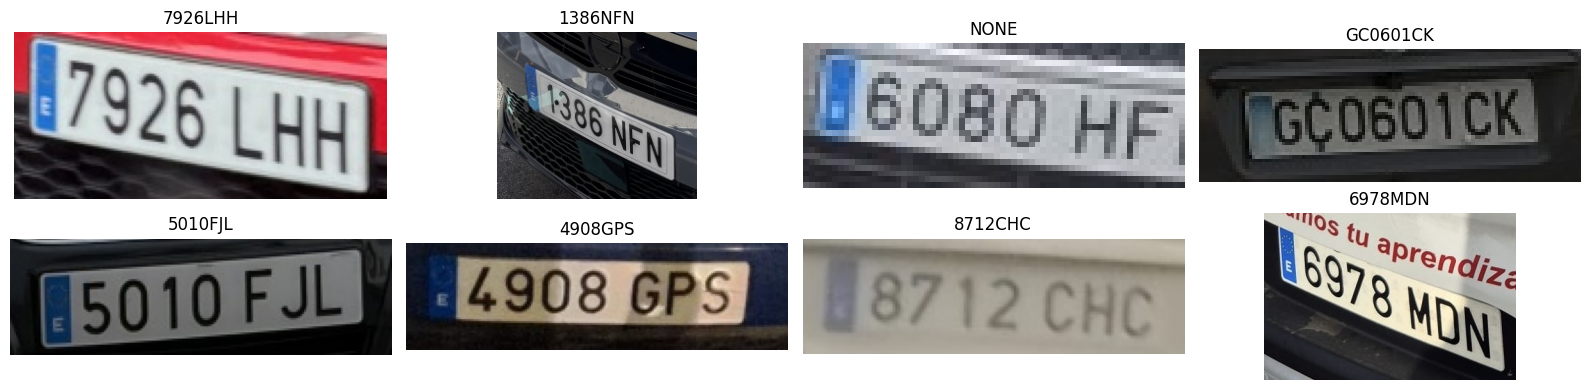

In [5]:
# 8 recortes al azar con su texto real, para comprobar que recorte y texto coinciden
gt = pd.read_csv(GT_CSV, dtype=str)

fig, axes = plt.subplots(2, 4, figsize=(16, 4))
for ax, (_, f) in zip(axes.flat, gt.sample(8, random_state=SEED).iterrows()):
    ax.imshow(cv2.cvtColor(cargar_imagen(RECORTES_DIR / f["recorte"]), cv2.COLOR_BGR2RGB))
    ax.set_title(f["texto_real"])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"

easyocr_reader = easyocr.Reader(["es"], gpu=(device == "cuda"))


# Devuelve (texto en bruto, matrícula normalizada)
def leer_easyocr(img):
    res = easyocr_reader.readtext(img, allowlist=ALLOWLIST)
    if not res:
        return "", ""
    
    res = sorted(res, key=lambda r: min(p[0] for p in r[0])) # EasyOCR lee la matrícula en trozos: se unen de izquierda a derecha
    bruto = " ".join(r[1] for r in res)
    return bruto, normalizar_matricula(bruto)

In [7]:
paddle_reader = PaddleOCR(
    lang="en",
    device="gpu" if device == "cuda" else "cpu",
    ocr_version="PP-OCRv5",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)


# Devuelve (texto en bruto, matrícula normalizada)
def leer_paddle(img):
    trozos = []
    for r in paddle_reader.predict(img):
        data = r.json
        data = data.get("res", data)
        textos = data.get("rec_texts", [])
        cajas = data.get("rec_boxes", [[0]] * len(textos))
        trozos += [(c[0], t) for t, c in zip(textos, cajas)]     # (x izquierda, texto)
    if not trozos:
        return "", ""
    # Se unen todos los trozos de izquierda a derecha
    bruto = " ".join(t for _, t in sorted(trozos, key=lambda x: x[0]))
    return bruto, normalizar_matricula(bruto)

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\alici\.paddlex\official_models\PP-OCRv5_server_det`.
c:\Users\alici\anaconda3\envs\VC_P4\lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:711: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('en_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\alici\.paddlex\official_models\en_PP-OCRv5_mobile_rec`.


In [8]:
MODEL_ID = "HuggingFaceTB/SmolVLM-Instruct"

# Imágenes de como mucho 768 px (por defecto las amplía a 1536 y las trocea: más lento sin ganar nada)
processor = AutoProcessor.from_pretrained(MODEL_ID, size={"longest_edge": 768})

# "sdpa" en lugar de "flash_attention_2", que no se puede instalar en Windows
vlm = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=torch.bfloat16,
                                                  _attn_implementation="sdpa").to(device)

PREGUNTA = ("Read the license plate. Return only the exact characters. "
            "If unreadable, return NONE.")


# Devuelve (texto en bruto, matrícula normalizada)
def leer_vlm(img):
    imagen = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    mensajes = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PREGUNTA}]}]
    prompt = processor.apply_chat_template(mensajes, add_generation_prompt=True)

    inputs = processor(text=prompt, images=[imagen], return_tensors="pt").to(device)
    inputs["pixel_values"] = inputs["pixel_values"].to(vlm.dtype)    # mismo tipo que el modelo

    with torch.inference_mode():
        generado = vlm.generate(**inputs, max_new_tokens=20, do_sample=False)

    generado = generado[:, inputs["input_ids"].shape[1]:]            # solo la respuesta, sin la pregunta
    bruto = processor.batch_decode(generado, skip_special_tokens=True)[0].strip()
    return bruto, normalizar_matricula(bruto)

In [10]:
modelos = {"EasyOCR": leer_easyocr, "PaddleOCR": leer_paddle, "SmolVLM": leer_vlm}
CAMPOS = ["modelo", "recorte", "texto_real", "salida_bruta", "prediccion", "acierto", "cer", "tiempo_ms"]


# Ejecuta el OCR y devuelve (resultado, ms), esperando a que la GPU termine para medir bien
def medir(funcion, img):
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    salida = funcion(img)
    if device == "cuda":
        torch.cuda.synchronize()
    return salida, (time.perf_counter() - t0) * 1000


gt = pd.read_csv(GT_CSV, dtype=str)

# Calentamiento: las primeras inferencias son más lentas y no se cuentan
for funcion in modelos.values():
    for nombre in gt["recorte"].head(3):
        funcion(preparar_recorte(cargar_imagen(RECORTES_DIR / nombre)))

# Si la ejecución se cortó, se continúa donde se quedó
hechos = set()
if RESULTADOS_CSV.exists():
    previo = pd.read_csv(RESULTADOS_CSV, dtype=str)
    hechos = set(zip(previo["modelo"], previo["recorte"]))

with open(RESULTADOS_CSV, "a", newline="", encoding="utf-8") as f_csv:
    escritor = csv.DictWriter(f_csv, fieldnames=CAMPOS)
    if not hechos:
        escritor.writeheader()

    for modelo, funcion in modelos.items():
        pendientes = [r for r in gt.itertuples() if (modelo, r.recorte) not in hechos]
        print(f"{modelo}: {len(pendientes)} matrículas pendientes")

        for n, r in enumerate(pendientes, 1):
            img = preparar_recorte(cargar_imagen(RECORTES_DIR / r.recorte))   # mismo recorte para los tres
            (bruto, pred), ms = medir(funcion, img)
            escritor.writerow({
                "modelo": modelo,
                "recorte": r.recorte,
                "texto_real": r.texto_real,
                "salida_bruta": bruto,
                "prediccion": pred,
                "acierto": pred == r.texto_real,
                "cer": min(1.0, levenshtein(pred, r.texto_real) / len(r.texto_real)),  # tasa de error por carácter
                "tiempo_ms": round(ms, 2),
            })
            f_csv.flush()                    # se guarda cada fila al momento
            if n % 100 == 0:
                print(f"  {modelo}: {n}/{len(pendientes)}")

print("Terminado. Resultados en", RESULTADOS_CSV)

EasyOCR: 0 matrículas pendientes
PaddleOCR: 0 matrículas pendientes
SmolVLM: 0 matrículas pendientes
Terminado. Resultados en ocr_eval\resultados_ocr.csv


In [ ]:
res = pd.read_csv(RESULTADOS_CSV, keep_default_na=False)
res["acierto"] = res["acierto"].astype(str) == "True"

metricas = res.groupby("modelo").agg(
    matriculas=("acierto", "size"),
    tasa_acierto=("acierto", "mean"),                        # matrícula completa correcta
    precision_caracteres=("cer", lambda c: 1 - c.mean()),    # 1 - tasa de error por carácter
    sin_lectura=("prediccion", lambda p: (p == "").mean()),  # no devolvió ninguna matrícula válida
    tiempo_medio_ms=("tiempo_ms", "mean"),
    tiempo_mediana_ms=("tiempo_ms", "median"),
)
metricas["matriculas_por_segundo"] = 1000 / metricas["tiempo_medio_ms"]

display(metricas.round(3))

,matriculas,tasa_acierto,precision_caracteres,sin_lectura,tiempo_medio_ms,tiempo_mediana_ms,matriculas_por_segundo
modelo,,,,,,,
EasyOCR,1788,0.562,0.717,0.232,18.561,15.665,53.877
PaddleOCR,1788,0.902,0.932,0.054,17.413,14.900,57.427
SmolVLM,1788,0.740,0.851,0.116,629.972,585.715,1.587


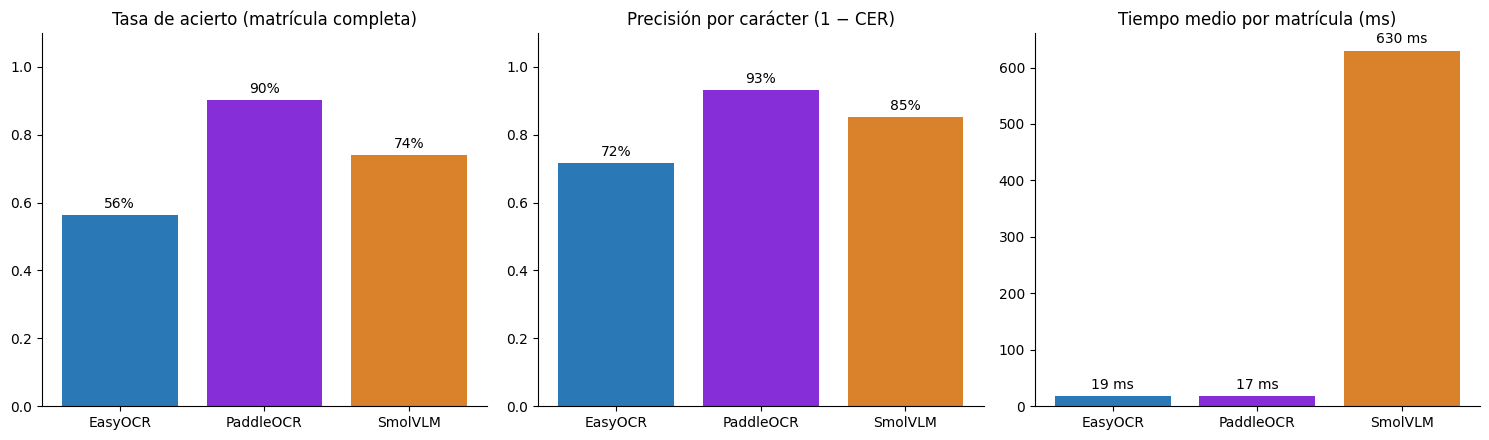

C:\Users\alici\AppData\Local\Temp\ipykernel_20388\416650063.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([res.loc[res.modelo == m, "tiempo_ms"] for m in orden], labels=orden)


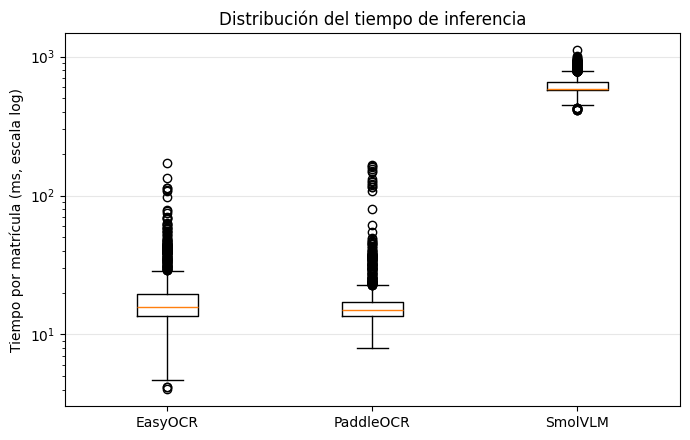

In [12]:
orden = list(metricas.index)
colores = {"EasyOCR": "#2a78b5", "PaddleOCR":  "#862fd8", "SmolVLM": "#d9822b"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, titulo, fmt) in zip(axes, [
        ("tasa_acierto", "Tasa de acierto (matrícula completa)", "{:.0%}"),
        ("precision_caracteres", "Precisión por carácter (1 − CER)", "{:.0%}"),
        ("tiempo_medio_ms", "Tiempo medio por matrícula (ms)", "{:.0f} ms")]):
    valores = metricas.loc[orden, col]
    barras = ax.bar(orden, valores, color=[colores[m] for m in orden])
    for b, v in zip(barras, valores):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), ha="center",
                    va="bottom", xytext=(0, 3), textcoords="offset points")
    ax.set_title(titulo)
    if col != "tiempo_medio_ms":
        ax.set_ylim(0, 1.1)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(EVAL_DIR / "comparativa_metricas.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([res.loc[res.modelo == m, "tiempo_ms"] for m in orden], labels=orden)
ax.set_yscale("log")
ax.set_ylabel("Tiempo por matrícula (ms, escala log)")
ax.set_title("Distribución del tiempo de inferencia")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(EVAL_DIR / "comparativa_tiempos.png", dpi=150)
plt.show()

In [13]:
print("Sistema     :", platform.system(), platform.release())
print("CPU         :", platform.processor(), f"({psutil.cpu_count(logical=False)} núcleos)")
print("RAM         :", f"{psutil.virtual_memory().total / 1e9:.1f} GB")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU         :", p.name, f"({p.total_memory / 1e9:.1f} GB)")
print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("EasyOCR     :", easyocr.__version__)
print("Transformers:", transformers.__version__)

Sistema     : Windows 10
CPU         : Intel64 Family 6 Model 183 Stepping 1, GenuineIntel (10 núcleos)
RAM         : 34.1 GB
GPU         : NVIDIA GeForce RTX 3050 (6.4 GB)
Python      : 3.9.25
PyTorch     : 2.5.1+cu121
EasyOCR     : 1.7.2
Transformers: 4.57.6
